# Compare training runs: loss curves

How do training and held-out losses change as optimization proceeds?
This notebook reads local `metrics.csv` and `metadata.json` files from both MLX
and PyTorch runs. It does not load checkpoints, fetch data, or modify a run.

Install plotting support in the notebook kernel's environment if needed:
`%pip install -e '.[analysis]'` (from the repository root), then restart the kernel.
An existing Jupyter/VS Code notebook environment is sufficient; the extra adds
Matplotlib only.

The training loss is **one batch at each logged step**, not the mean since the
previous log. Validation loss averages the configured fixed validation batches.
Step zero has validation loss only. A running file is a snapshot: only complete
CSV lines are read. Rerun the final cell to refresh; no automatic polling.

Implementation references: [local metric writer](../src/llm_training/pretraining/tracking.py),
[MLX training loop](../src/llm_training/pretraining_mlx/train.py), and
[Matplotlib plotting API](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html).


In [ ]:
from pathlib import Path
import csv
import io
import json
import math
import warnings

import matplotlib.pyplot as plt

# Works when the kernel starts in the repo root or in notebooks/.
repo_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file() and (p / "src/llm_training").is_dir()),
    None,
)
if repo_root is None:
    raise RuntimeError("Start the notebook inside the learning_llm_training repository")
runs_root = repo_root / "artifacts/pretraining"
print(f"Reading: {runs_root}")


Reading: /Users/mikhail.n/Desktop/learning/learning_llm_training/artifacts/pretraining


In [ ]:
def read_run(run_dir):
    # Read once so a concurrent append cannot change the data halfway through parsing.
    lines = (run_dir / "metrics.csv").read_text(encoding="utf-8").splitlines(keepends=True)
    if lines and not lines[-1].endswith("\n"):
        lines.pop()  # A writer may still be finishing its last row.
    reader = csv.DictReader(io.StringIO("".join(lines)))
    expected = {"step", "train_loss", "val_loss"}
    if reader.fieldnames is None:
        return [], {}  # A newly created file may not have its header yet.
    if set(reader.fieldnames) != expected:
        raise ValueError(f"Unexpected CSV columns in {run_dir / 'metrics.csv'}")
    rows = []
    for row in reader:
        try:
            step = int(row["step"])
            train_loss = float(row["train_loss"]) if row["train_loss"] else None
            val_loss = float(row["val_loss"])
            if (step < 0 or not math.isfinite(val_loss)
                    or (train_loss is not None and not math.isfinite(train_loss))):
                raise ValueError("non-finite loss or negative step")
        except (TypeError, ValueError) as error:
            warnings.warn(f"Skipping invalid metrics row in {run_dir.name}: {row!r}: {error}")
            continue
        rows.append({"step": step, "train_loss": train_loss, "val_loss": val_loss})
    try:
        metadata = json.loads((run_dir / "metadata.json").read_text(encoding="utf-8"))
    except (FileNotFoundError, json.JSONDecodeError):
        # Status metadata is rewritten at run completion; retry on the next refresh.
        metadata = {}
    return rows, metadata


def rolling_mean(values, window):
    # This averages logged observations, not all optimizer-step losses.
    return [sum(values[max(0, i - window + 1):i + 1]) / min(window, i + 1)
            for i in range(len(values))]


print("Available runs:")
for path in sorted(runs_root.glob("*/metrics.csv")):
    print(" ", path.parent.name)


Available runs:
  tiny-gpt-mlx-run-01
  tiny-gpt-mlx-run-02
  tiny-gpt-mlx-run-03
  tiny-gpt-mlx-run-04
  tiny-gpt-mlx-run-05
  tiny-gpt-mlx-run-06


In [ ]:
# Empty selects all runs with metrics. Use exact folder names to limit the plot.
selected_names = []  # e.g. ["tiny-gpt-mlx-run-02", "tiny-gpt-mlx-run-03"]
start_step = 0       # e.g. 100 to zoom past the initial loss drop
smooth_window = 1    # >1 overlays a mean over this many logged training observations


Run                                  Status          Step   Last val   Best val  Best step
tiny-gpt-mlx-run-01                  completed          5     8.8095     8.8095          5
tiny-gpt-mlx-run-02                  completed       5000     5.5790     5.5790       5000
tiny-gpt-mlx-run-03                  completed       5000     5.3375     5.3375       5000
tiny-gpt-mlx-run-04                  completed       5000     5.3375     5.3375       5000
tiny-gpt-mlx-run-05                  completed      50000     4.5403     4.5196      49550
tiny-gpt-mlx-run-06                  running       184300     4.3872     4.3704     148700

tiny-gpt-mlx-run-01: backend=mlx, tokenizer=07f8f1d773a508decf1cc64613d75a98a358753f7b0a0177d7e52c562c7061bd
  model_config: {'vocab_size': 8000, 'context_length': 128, 'n_layers': 4, 'n_heads': 4, 'd_model': 128}
  training_config: {'steps': 5, 'batch_size': 8, 'learning_rate': 0.0003, 'weight_decay': 0.1, 'grad_clip': 1.0, 'eval_every': 50, 'eval_batches': 1

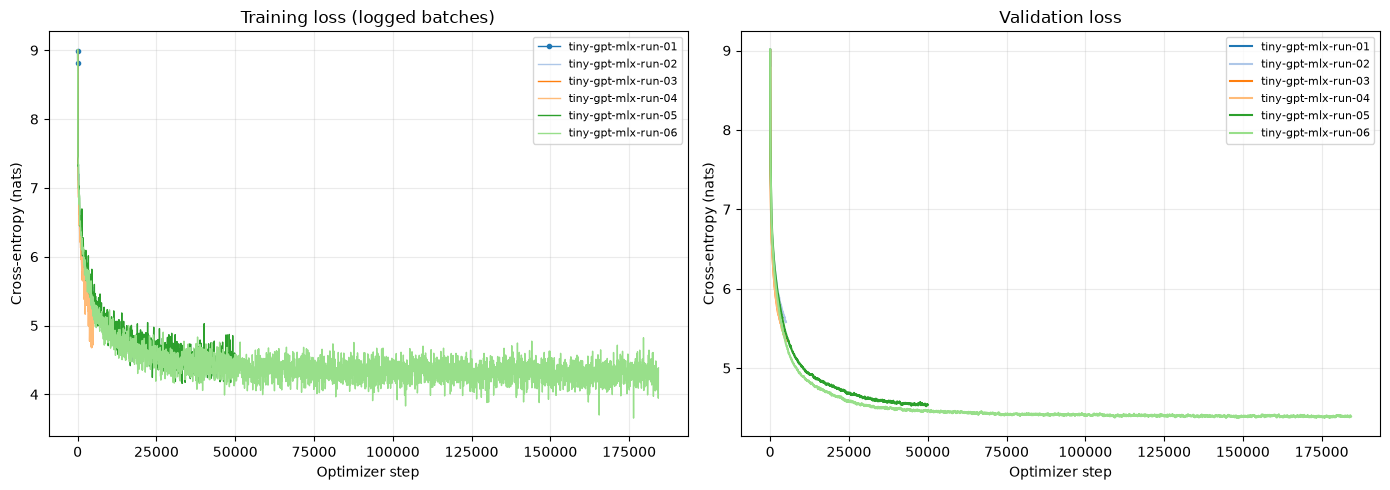

In [ ]:
# RERUN THIS CELL to refresh both the summary and plots while training continues.
if smooth_window < 1 or not isinstance(smooth_window, int) or start_step < 0:
    raise ValueError("smooth_window must be a positive integer and start_step nonnegative")
paths = sorted(runs_root.glob("*/metrics.csv"))
available = {p.parent.name: p.parent for p in paths}
missing = set(selected_names) - set(available)
if missing:
    raise ValueError(f"No metrics.csv for selected runs: {sorted(missing)}")
names = selected_names or list(available)
runs = {name: read_run(available[name]) for name in names}

# Summarize all recorded steps, independently of the plotted start_step.
print(f"{'Run':36} {'Status':12} {'Step':>7} {'Last val':>10} {'Best val':>10} {'Best step':>10}")
for name, (rows, metadata) in runs.items():
    if not rows:
        print(f"{name}: no complete metrics rows yet")
        continue
    best = min(rows, key=lambda r: r["val_loss"])
    last = rows[-1]
    print(f"{name:36} {metadata.get('status', 'unknown'):12} {last['step']:7d} "
          f"{last['val_loss']:10.4f} {best['val_loss']:10.4f} {best['step']:10d}")

# Read settings before attributing a loss difference to a training change.
for name, (_, metadata) in runs.items():
    print(f"\n{name}: backend={metadata.get('backend', 'torch')}, "
          f"tokenizer={metadata.get('tokenizer_sha256', 'unknown')}")
    for field in ("model_config", "training_config", "data_config"):
        print(f"  {field}: {metadata.get(field, 'unavailable')}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for index, (name, (rows, _)) in enumerate(runs.items()):
    color = plt.get_cmap("tab20")(index % 20)
    visible = [row for row in rows if row["step"] >= start_step]
    train_rows = [row for row in visible if row["train_loss"] is not None]
    if train_rows:
        steps = [r["step"] for r in train_rows]
        losses = [r["train_loss"] for r in train_rows]
        axes[0].plot(steps, losses, color=color, alpha=0.3 if smooth_window > 1 else 1,
                     linewidth=1, marker="." if len(steps) < 3 else None,
                     label=name if smooth_window == 1 else None)
        if smooth_window > 1:
            axes[0].plot(steps, rolling_mean(losses, smooth_window), color=color, label=name)
    if visible:
        axes[1].plot([r["step"] for r in visible], [r["val_loss"] for r in visible],
                     color=color, label=name, marker="." if len(visible) < 3 else None)
for ax, title in zip(axes, ("Training loss (logged batches)", "Validation loss")):
    ax.set(title=title, xlabel="Optimizer step", ylabel="Cross-entropy (nats)")
    ax.grid(alpha=0.25)
    if ax.lines:
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, "No recorded points in this range", ha="center", transform=ax.transAxes)
fig.tight_layout()
plt.show()
